<a href="https://colab.research.google.com/github/souvikdey214-code/Krutanic_Weekly-Project-Task/blob/main/06_Outbreak_Cast.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_percentage_error

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf

from pmdarima import auto_arima

from prophet import Prophet

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("Libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

Libraries imported successfully!
TensorFlow version: 2.21.0


In [ ]:
df = pd.read_csv("COVID-19 Dataset.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

Dataset loaded successfully!
Dataset shape: (617667, 61)

Available columns:
['country', 'date', 'total_cases', 'new_cases', 'new_cases_smoothed', 'total_cases_per_million', 'new_cases_per_million', 'new_cases_smoothed_per_million', 'total_deaths', 'new_deaths', 'new_deaths_smoothed', 'total_deaths_per_million', 'new_deaths_per_million', 'new_deaths_smoothed_per_million', 'excess_mortality', 'excess_mortality_cumulative', 'excess_mortality_cumulative_absolute', 'excess_mortality_cumulative_per_million', 'hosp_patients', 'hosp_patients_per_million', 'weekly_hosp_admissions', 'weekly_hosp_admissions_per_million', 'icu_patients', 'icu_patients_per_million', 'weekly_icu_admissions', 'weekly_icu_admissions_per_million', 'stringency_index', 'reproduction_rate', 'total_tests', 'new_tests', 'total_tests_per_thousand', 'new_tests_per_thousand', 'new_tests_smoothed', 'new_tests_smoothed_per_thousand', 'positive_rate', 'tests_per_case', 'total_vaccinations', 'people_vaccinated', 'people_fully_vac

In [ ]:
india = df[df["country"] == "India"].copy()

print("India data loaded successfully!")
print("Number of records:", len(india))

India data loaded successfully!
Number of records: 2434


In [ ]:
india = india[["date", "new_cases"]].copy()

india["date"] = pd.to_datetime(india["date"])

india = india.sort_values("date")

india["new_cases"] = india["new_cases"].fillna(0)

india.set_index("date", inplace=True)

print(india.head())

            new_cases
date                 
2020-01-01        0.0
2020-01-02        0.0
2020-01-03        0.0
2020-01-04        0.0
2020-01-05        0.0


In [ ]:
india["new_cases"] = india["new_cases"].clip(lower=0)

india = india.asfreq("D")

india["new_cases"] = india["new_cases"].fillna(0)

print("Missing values:")
print(india.isnull().sum())

Missing values:
new_cases    0
dtype: int64


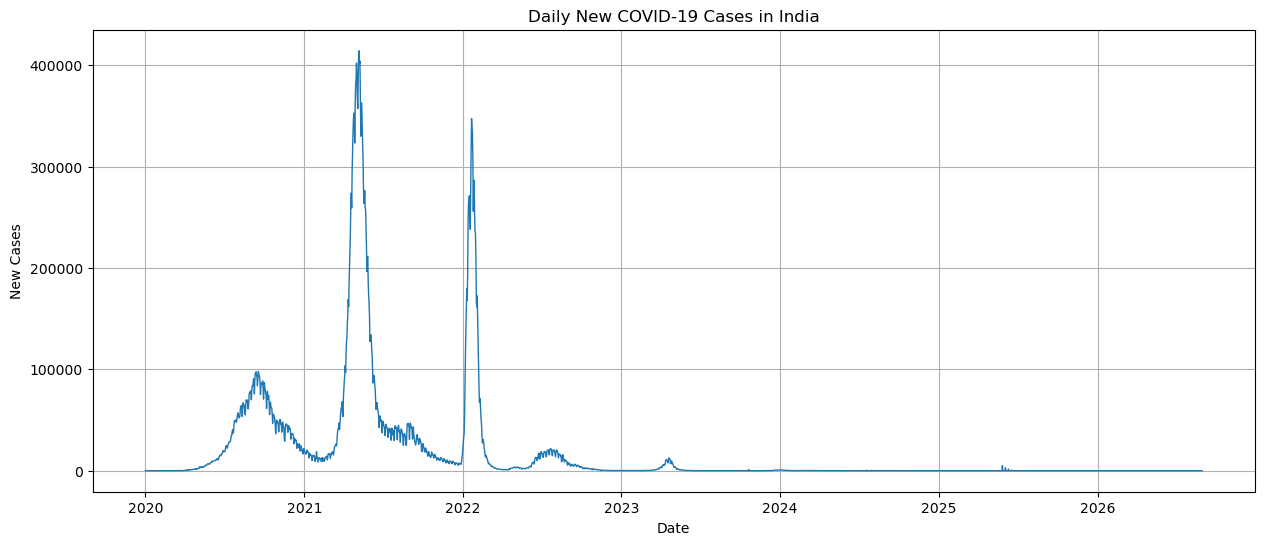

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(
    india.index,
    india["new_cases"],
    linewidth=1
)

plt.title("Daily New COVID-19 Cases in India")
plt.xlabel("Date")
plt.ylabel("New Cases")

plt.grid(True)
plt.show()

In [ ]:
india["rolling_7"] = (
    india["new_cases"]
    .rolling(window=7)
    .mean()
)

india["rolling_7"] = india["rolling_7"].bfill()

print(india[["new_cases", "rolling_7"]].head(10))

            new_cases  rolling_7
date                            
2020-01-01        0.0        0.0
2020-01-02        0.0        0.0
2020-01-03        0.0        0.0
2020-01-04        0.0        0.0
2020-01-05        0.0        0.0
2020-01-06        0.0        0.0
2020-01-07        0.0        0.0
2020-01-08        0.0        0.0
2020-01-09        0.0        0.0
2020-01-10        0.0        0.0


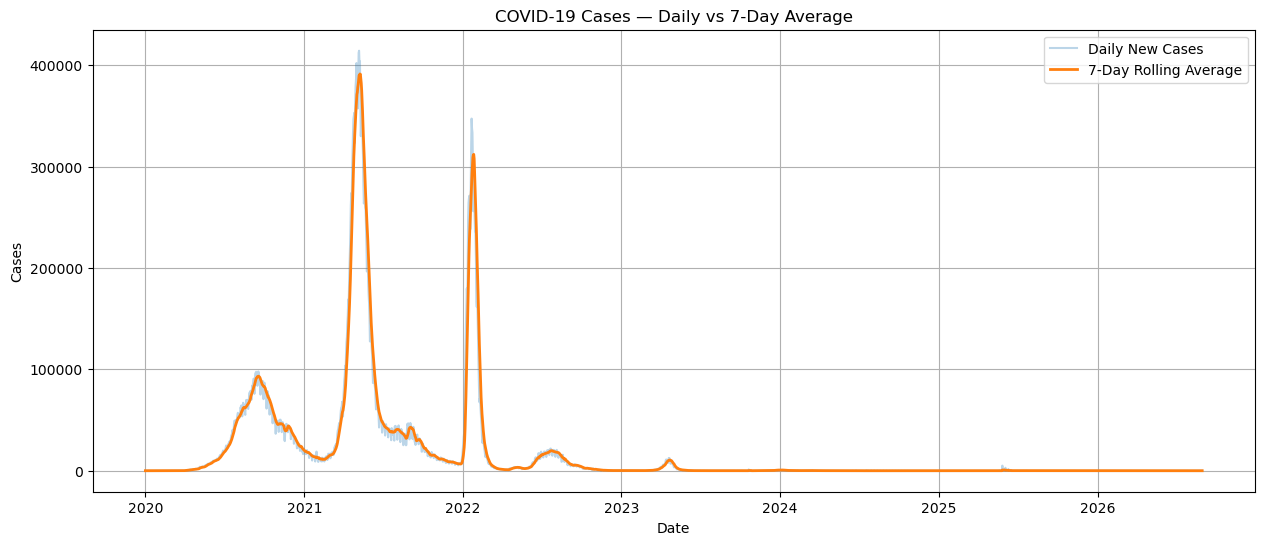

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(
    india.index,
    india["new_cases"],
    alpha=0.3,
    label="Daily New Cases"
)

plt.plot(
    india.index,
    india["rolling_7"],
    linewidth=2,
    label="7-Day Rolling Average"
)

plt.title("COVID-19 Cases — Daily vs 7-Day Average")
plt.xlabel("Date")
plt.ylabel("Cases")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
series = india["rolling_7"].copy()

series = series.dropna()

print("Total observations:", len(series))
print("Start date:", series.index.min())
print("End date:", series.index.max())

Total observations: 2434
Start date: 2020-01-01 00:00:00
End date: 2026-08-30 00:00:00


In [ ]:
def adf_test(data, name="Time Series"):

    result = adfuller(data.dropna(), autolag="AIC")

    print("ADF Test:", name)
    print("--------------------------------")
    print("ADF Statistic:", result[0])
    print("p-value:", result[1])

    print("\nCritical Values:")

    for key, value in result[4].items():
        print(f"{key}: {value}")

    if result[1] < 0.05:
        print("\nResult: Series is stationary.")
    else:
        print("\nResult: Series is non-stationary.")

    return result


adf_result = adf_test(series)

ADF Test: Time Series
--------------------------------
ADF Statistic: -5.371342527648375
p-value: 3.8896838656008865e-06

Critical Values:
1%: -3.433068556739703
5%: -2.86274102375869
10%: -2.5674093548705312

Result: Series is stationary.


In [ ]:
differenced_series = series.diff().dropna()

adf_diff_result = adf_test(
    differenced_series,
    "First Differenced Series"
)

ADF Test: First Differenced Series
--------------------------------
ADF Statistic: -8.44536758989472
p-value: 1.7185962289214786e-13

Critical Values:
1%: -3.4330719515006027
5%: -2.8627425228363728
10%: -2.5674101530076374

Result: Series is stationary.


<Figure size 1200x500 with 0 Axes>

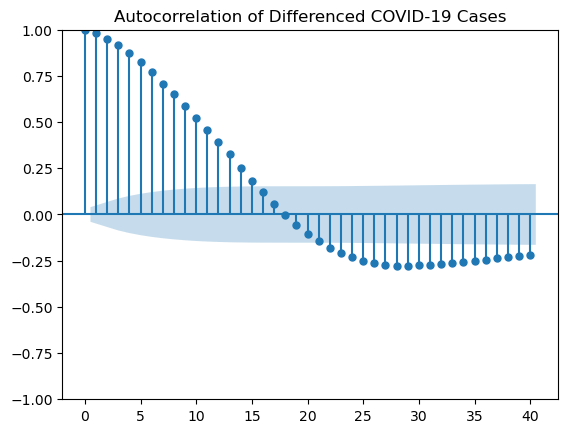

In [ ]:
plt.figure(figsize=(12, 5))

plot_acf(
    differenced_series,
    lags=40
)

plt.title("Autocorrelation of Differenced COVID-19 Cases")

plt.show()

In [ ]:
split_index = int(len(series) * 0.80)

train = series.iloc[:split_index]
test = series.iloc[split_index:]

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting period:")
print(test.index.min(), "to", test.index.max())

Training observations: 1947
Testing observations: 487

Training period:
2020-01-01 00:00:00 to 2025-04-30 00:00:00

Testing period:
2025-05-01 00:00:00 to 2026-08-30 00:00:00


In [ ]:
print("Searching for best ARIMA parameters...")

arima_model = auto_arima(
    train,
    seasonal=False,
    stepwise=True,
    suppress_warnings=True,
    error_action="ignore",
    trace=True,
    max_p=5,
    max_q=5,
    max_d=2
)

print("\nBest ARIMA Model:")
print(arima_model.order)

Searching for best ARIMA parameters...
Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=29931.412, Time=2.16 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=36447.515, Time=0.03 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=30181.979, Time=0.07 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=34177.647, Time=0.70 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=36445.516, Time=0.02 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=30102.616, Time=0.99 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=29930.136, Time=0.79 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=30113.833, Time=0.70 sec
 ARIMA(2,1,0)(0,0,0)[0] intercept   : AIC=30098.908, Time=0.10 sec
 ARIMA(3,1,1)(0,0,0)[0] intercept   : AIC=29931.552, Time=1.70 sec
 ARIMA(3,1,0)(0,0,0)[0] intercept   : AIC=30069.617, Time=0.13 sec
 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=3.47 sec
 ARIMA(2,1,1)(0,0,0)[0]             : AIC=29928.136, Time=0.41 sec
 ARIMA(1,1,1)(0,0,0)[0]             : AIC=30111.833, 

In [ ]:
arima_forecast, conf_int = arima_model.predict(
    n_periods=len(test),
    return_conf_int=True
)

arima_forecast = pd.Series(
    arima_forecast,
    index=test.index
)

print(arima_forecast.head())

date
2025-05-01    11.593776
2025-05-02    11.086176
2025-05-03    10.354653
2025-05-04     9.420422
2025-05-05     8.305337
Freq: D, dtype: float64


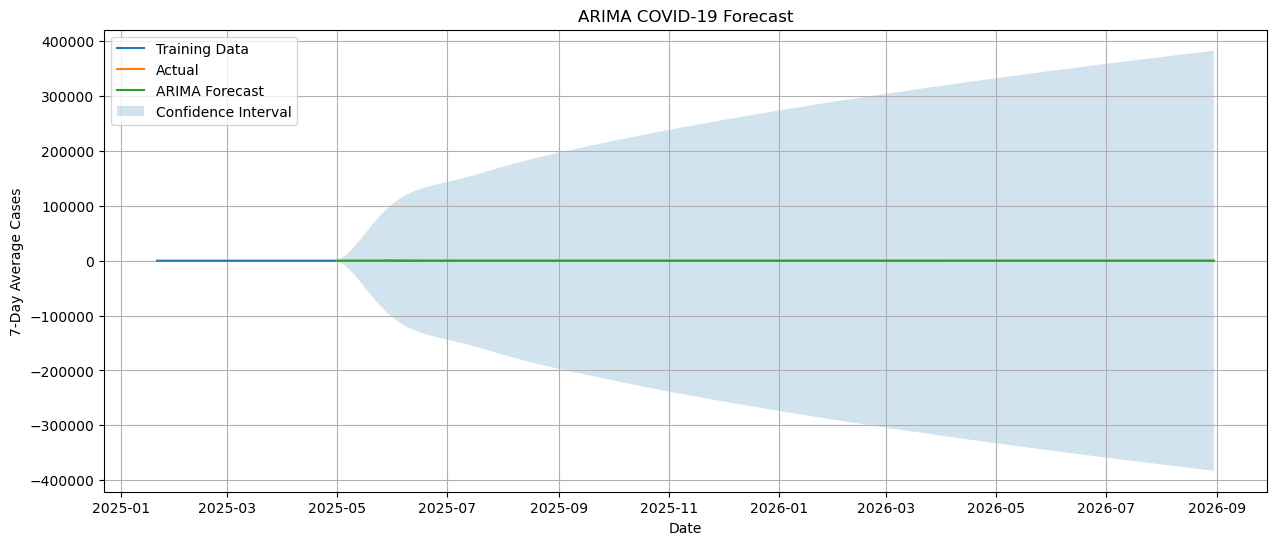

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(
    train.index[-100:],
    train.iloc[-100:],
    label="Training Data"
)

plt.plot(
    test.index,
    test,
    label="Actual"
)

plt.plot(
    arima_forecast.index,
    arima_forecast,
    label="ARIMA Forecast"
)

plt.fill_between(
    test.index,
    conf_int[:, 0],
    conf_int[:, 1],
    alpha=0.2,
    label="Confidence Interval"
)

plt.title("ARIMA COVID-19 Forecast")
plt.xlabel("Date")
plt.ylabel("7-Day Average Cases")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
def safe_mape(actual, predicted):

    actual = np.array(actual)
    predicted = np.array(predicted)

    mask = actual != 0

    return (
        np.mean(
            np.abs(
                (actual[mask] - predicted[mask])
                / actual[mask]
            )
        ) * 100
    )


arima_mape = safe_mape(
    test,
    arima_forecast
)

print(f"ARIMA MAPE: {arima_mape:.2f}%")

ARIMA MAPE: 1306.06%


In [ ]:
from prophet import Prophet

print("Prophet imported successfully!")

Prophet imported successfully!


In [ ]:
prophet_data = series.reset_index()

prophet_data.columns = ["ds", "y"]

print(prophet_data.head())

          ds    y
0 2020-01-01  0.0
1 2020-01-02  0.0
2 2020-01-03  0.0
3 2020-01-04  0.0
4 2020-01-05  0.0


In [ ]:
prophet_train = prophet_data.iloc[:split_index].copy()

prophet_test = prophet_data.iloc[split_index:].copy()

print("Prophet training rows:", len(prophet_train))
print("Prophet testing rows:", len(prophet_test))

Prophet training rows: 1947
Prophet testing rows: 487


In [ ]:
prophet_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)

prophet_model.fit(prophet_train)

print("Prophet model trained successfully!")

21:45:23 - cmdstanpy - INFO - Chain [1] start processing
21:45:24 - cmdstanpy - INFO - Chain [1] done processing


Prophet model trained successfully!


In [ ]:
future = prophet_model.make_future_dataframe(
    periods=len(prophet_test),
    freq="D"
)

prophet_forecast_full = prophet_model.predict(future)

prophet_forecast = (
    prophet_forecast_full
    .set_index("ds")["yhat"]
    .loc[prophet_test["ds"]]
)

print(prophet_forecast.head())

ds
2025-05-01    45997.809367
2025-05-02    47626.180587
2025-05-03    49068.336751
2025-05-04    50306.436841
2025-05-05    51325.490219
Name: yhat, dtype: float64


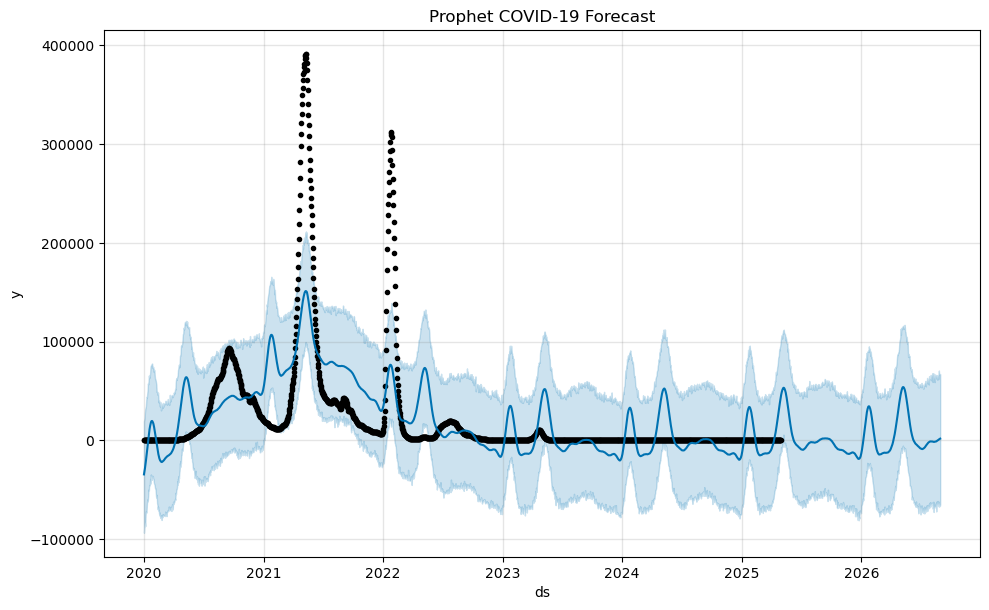

In [ ]:
fig = prophet_model.plot(
    prophet_forecast_full
)

plt.title("Prophet COVID-19 Forecast")

plt.show()

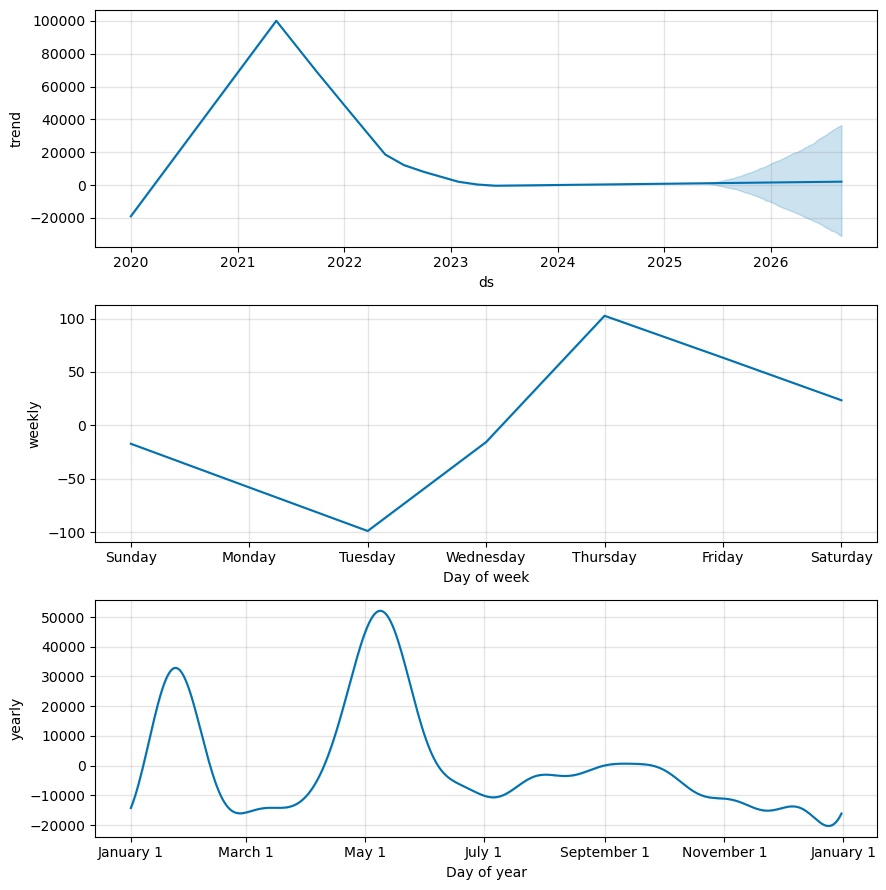

In [ ]:
fig = prophet_model.plot_components(
    prophet_forecast_full
)

plt.show()

In [ ]:
prophet_mape = safe_mape(
    prophet_test["y"].values,
    prophet_forecast.values
)

print(f"Prophet MAPE: {prophet_mape:.2f}%")

Prophet MAPE: 1160664.02%


In [ ]:
lstm_series = series.values.reshape(-1, 1)

scaler = MinMaxScaler()

scaled_data = scaler.fit_transform(lstm_series)

print("Scaled data shape:", scaled_data.shape)

Scaled data shape: (2434, 1)


In [ ]:
LOOKBACK = 30
FORECAST_HORIZON = 7

X = []
y = []

for i in range(
    LOOKBACK,
    len(scaled_data) - FORECAST_HORIZON + 1
):

    X.append(
        scaled_data[i - LOOKBACK:i, 0]
    )

    y.append(
        scaled_data[
            i:i + FORECAST_HORIZON,
            0
        ]
    )

X = np.array(X)
y = np.array(y)

X = X.reshape(
    X.shape[0],
    X.shape[1],
    1
)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (2398, 30, 1)
y shape: (2398, 7)


In [ ]:
lstm_split = int(len(X) * 0.80)

X_train = X[:lstm_split]
X_test = X[lstm_split:]

y_train = y[:lstm_split]
y_test = y[lstm_split:]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (1918, 30, 1)
y_train: (1918, 7)
X_test: (480, 30, 1)
y_test: (480, 7)


In [ ]:
lstm_model = Sequential()

lstm_model.add(
    LSTM(
        64,
        return_sequences=True,
        input_shape=(LOOKBACK, 1)
    )
)

lstm_model.add(
    LSTM(32)
)

lstm_model.add(
    Dense(7)
)

lstm_model.compile(
    optimizer="adam",
    loss="mse"
)

lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 30, 64)              │          16,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 32)                  │          12,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 7)                   │             231 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 29,543 (115.40 KB)

 Trainable params: 29,543 (115.40 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

In [ ]:
history = lstm_model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.10,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
54/54 ━━━━━━━━━━━━━━━━━━━━ 6s 50ms/step - loss: 0.0093 - val_loss: 9.4369e-05
Epoch 2/100
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0024 - val_loss: 2.2325e-05
Epoch 3/100
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0016 - val_loss: 7.1585e-05
Epoch 4/100
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0014 - val_loss: 1.1458e-04
Epoch 5/100
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0012 - val_loss: 7.7969e-05
Epoch 6/100
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 0.0011 - val_loss: 1.9087e-06
Epoch 7/100
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0010 - val_loss: 2.8998e-04
Epoch 8/100
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 9.9338e-04 - val_loss: 7.4634e-05
Epoch 9/100
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 9.0652e-04 - val_loss: 5.5577e-07
Epoch 10/100
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 8.5020e-04 - val_loss: 1.4298e-05
Epoch 11/100
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 8.2874e-04 - val_loss: 3.7

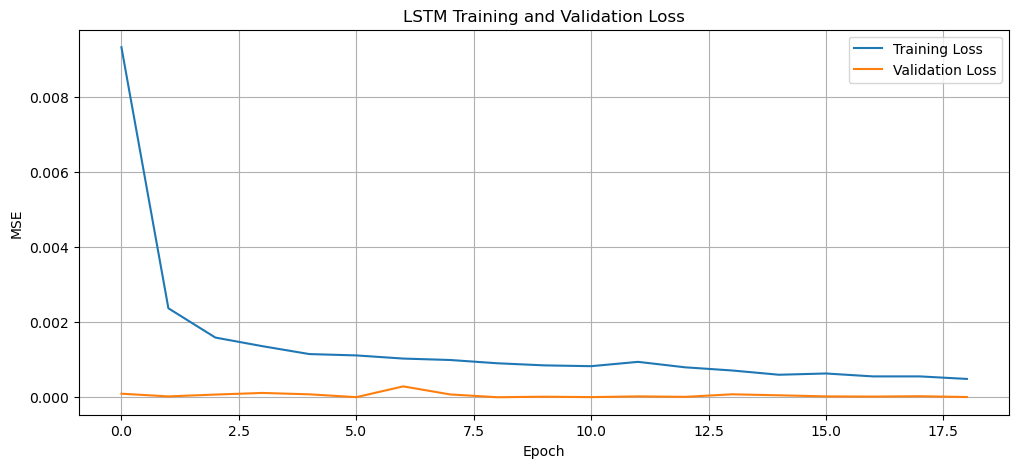

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
lstm_predictions_scaled = lstm_model.predict(
    X_test
)

print(
    "Prediction shape:",
    lstm_predictions_scaled.shape
)

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
Prediction shape: (480, 7)


In [ ]:
lstm_predictions = scaler.inverse_transform(
    lstm_predictions_scaled.reshape(-1, 1)
).reshape(
    lstm_predictions_scaled.shape
)

lstm_actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).reshape(
    y_test.shape
)

print("Predictions converted back to original scale.")

Predictions converted back to original scale.


In [ ]:
lstm_mape = safe_mape(
    lstm_actual.flatten(),
    lstm_predictions.flatten()
)

print(f"LSTM MAPE: {lstm_mape:.2f}%")

LSTM MAPE: 22298.68%


In [ ]:
comparison_actual = test.iloc[-7:]

comparison_arima = arima_forecast.iloc[-7:]

comparison_prophet = prophet_forecast.iloc[-7:]

In [ ]:
comparison_lstm = pd.Series(
    lstm_predictions[-1],
    index=comparison_actual.index
)

comparison_lstm

date
2026-08-24   -235.619141
2026-08-25   -217.829865
2026-08-26   -101.942635
2026-08-27   -350.597168
2026-08-28   -227.863831
2026-08-29   -436.873566
2026-08-30   -338.004913
Freq: D, dtype: float32

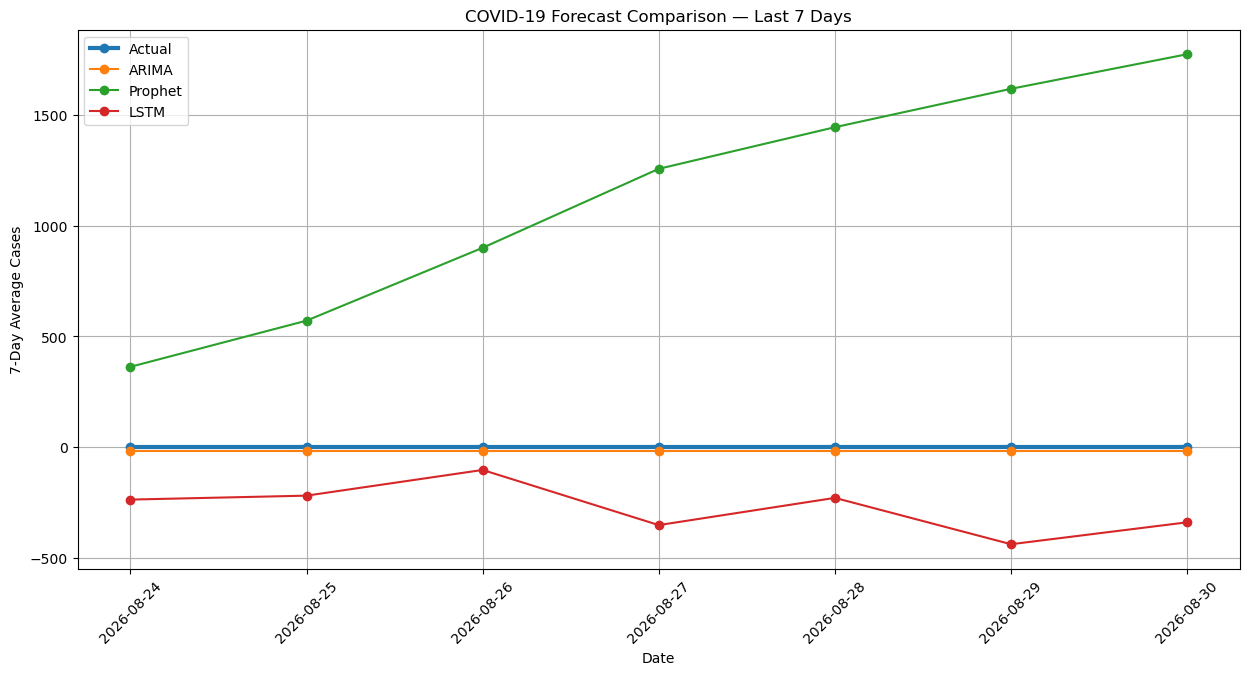

In [ ]:
plt.figure(figsize=(15, 7))

plt.plot(
    comparison_actual.index,
    comparison_actual.values,
    marker="o",
    linewidth=3,
    label="Actual"
)

plt.plot(
    comparison_arima.index,
    comparison_arima.values,
    marker="o",
    label="ARIMA"
)

plt.plot(
    comparison_prophet.index,
    comparison_prophet.values,
    marker="o",
    label="Prophet"
)

plt.plot(
    comparison_lstm.index,
    comparison_lstm.values,
    marker="o",
    label="LSTM"
)

plt.title(
    "COVID-19 Forecast Comparison — Last 7 Days"
)

plt.xlabel("Date")
plt.ylabel("7-Day Average Cases")

plt.legend()
plt.grid(True)

plt.xticks(rotation=45)

plt.show()

In [ ]:
results = pd.DataFrame({
    "Model": [
        "ARIMA",
        "Prophet",
        "LSTM"
    ],
    "MAPE (%)": [
        arima_mape,
        prophet_mape,
        lstm_mape
    ]
})

results = results.sort_values(
    "MAPE (%)"
).reset_index(drop=True)

results

,Model,MAPE (%)
0,ARIMA,1.306061e+03
1,LSTM,2.229868e+04
2,Prophet,1.160664e+06


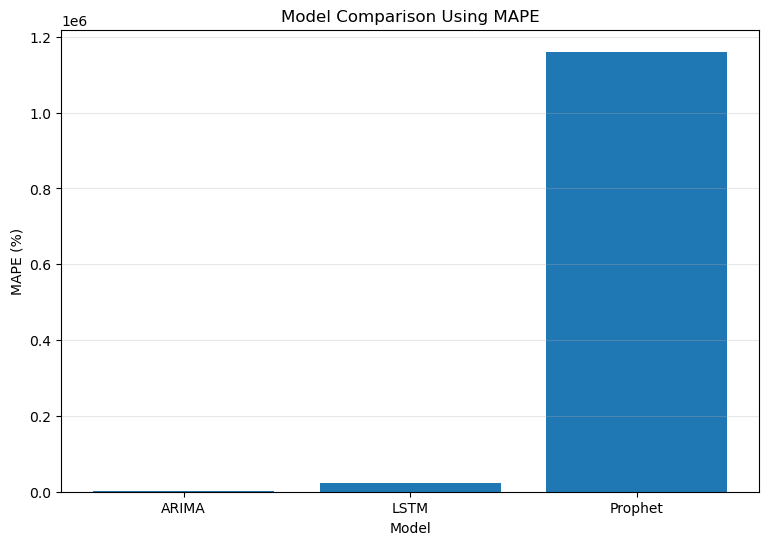

In [ ]:
plt.figure(figsize=(9, 6))

plt.bar(
    results["Model"],
    results["MAPE (%)"]
)

plt.title("Model Comparison Using MAPE")

plt.xlabel("Model")
plt.ylabel("MAPE (%)")

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

In [ ]:
def forecast_next_7_days(model, data, scaler):

    last_30 = data[-LOOKBACK:]

    scaled_last_30 = scaler.transform(
        last_30.reshape(-1, 1)
    )

    X_input = scaled_last_30.reshape(
        1,
        LOOKBACK,
        1
    )

    prediction_scaled = model.predict(
        X_input,
        verbose=0
    )

    prediction = scaler.inverse_transform(
        prediction_scaled.reshape(-1, 1)
    ).flatten()

    prediction = np.maximum(
        prediction,
        0
    )

    return prediction

In [ ]:
future_7_days = forecast_next_7_days(
    lstm_model,
    lstm_series,
    scaler
)

future_dates = pd.date_range(
    start=series.index[-1] + pd.Timedelta(days=1),
    periods=7,
    freq="D"
)

future_forecast = pd.Series(
    future_7_days,
    index=future_dates
)

print("Next 7 Days Forecast:")
print(future_forecast)

Next 7 Days Forecast:
2026-08-31    0.0
2026-09-01    0.0
2026-09-02    0.0
2026-09-03    0.0
2026-09-04    0.0
2026-09-05    0.0
2026-09-06    0.0
Freq: D, dtype: float32


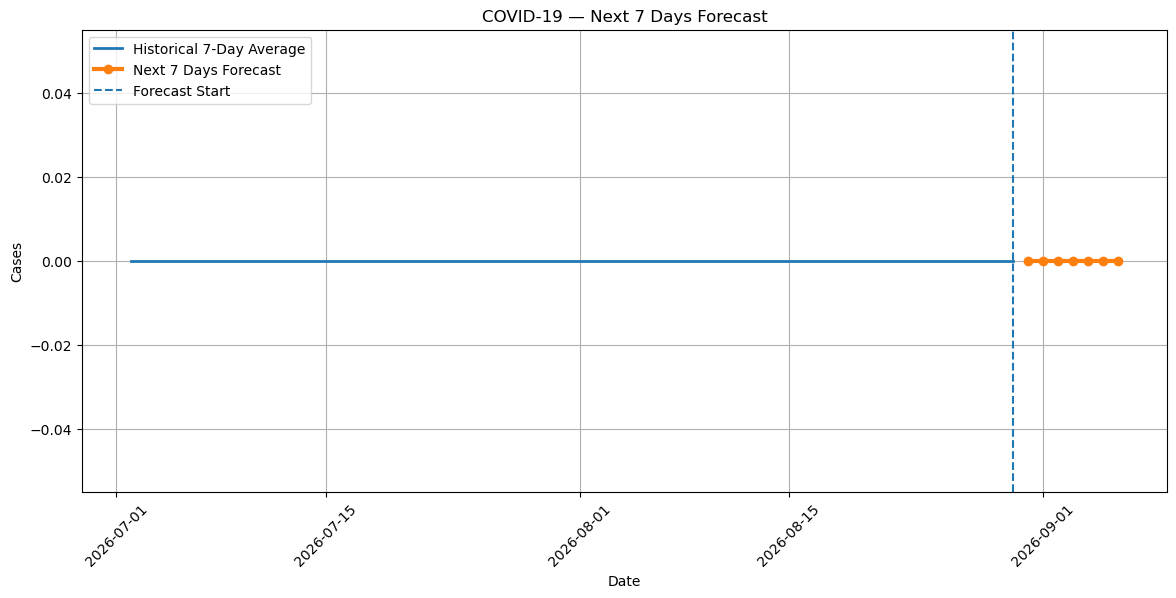

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    series.index[-60:],
    series.iloc[-60:],
    label="Historical 7-Day Average",
    linewidth=2
)

plt.plot(
    future_forecast.index,
    future_forecast.values,
    marker="o",
    linewidth=3,
    label="Next 7 Days Forecast"
)

plt.axvline(
    series.index[-1],
    linestyle="--",
    label="Forecast Start"
)

plt.title(
    "COVID-19 — Next 7 Days Forecast"
)

plt.xlabel("Date")
plt.ylabel("Cases")

plt.legend()
plt.grid(True)

plt.xticks(rotation=45)

plt.show()

In [ ]:
def surge_alert(
    historical_series,
    forecast_series,
    threshold=0.50
):

    current_average = historical_series.iloc[-7:].mean()

    forecast_average = forecast_series.mean()

    increase = (
        (forecast_average - current_average)
        / current_average
    )

    increase_percentage = increase * 100

    print("Current 7-Day Average:",
          f"{current_average:.2f}")

    print("Forecast 7-Day Average:",
          f"{forecast_average:.2f}")

    print("Expected Change:",
          f"{increase_percentage:.2f}%")

    print("\nAlert Status:")

    if increase >= threshold:
        print("🚨 SURGE ALERT")
        print(
            "Forecast indicates a 50% or greater increase."
        )
    else:
        print("✅ NO SURGE ALERT")
        print(
            "Forecast does not indicate a 50% or greater increase."
        )

    return increase_percentage

In [ ]:
surge_percentage = surge_alert(
    series,
    future_forecast
)

Current 7-Day Average: 0.00
Forecast 7-Day Average: 0.00
Expected Change: nan%

Alert Status:
✅ NO SURGE ALERT
Forecast does not indicate a 50% or greater increase.


In [ ]:
print("=" * 60)
print("COVID-19 SPREAD FORECASTING — FINAL RESULTS")
print("=" * 60)

print("\nMODEL PERFORMANCE")
print(results.to_string(index=False))

print("\nNEXT 7 DAYS FORECAST")
print(future_forecast.round(2))

print("\nSURGE ANALYSIS")

current_average = series.iloc[-7:].mean()
forecast_average = future_forecast.mean()

percentage_change = (
    (forecast_average - current_average)
    / current_average
) * 100

print(
    f"Current 7-Day Average : {current_average:.2f}"
)

print(
    f"Forecast 7-Day Average: {forecast_average:.2f}"
)

print(
    f"Expected Change       : {percentage_change:.2f}%"
)

if percentage_change >= 50:
    print("\n🚨 SURGE ALERT")
else:
    print("\n✅ NO SURGE ALERT")

COVID-19 SPREAD FORECASTING — FINAL RESULTS

MODEL PERFORMANCE
  Model     MAPE (%)
  ARIMA 1.306061e+03
   LSTM 2.229868e+04
Prophet 1.160664e+06

NEXT 7 DAYS FORECAST
2026-08-31    0.0
2026-09-01    0.0
2026-09-02    0.0
2026-09-03    0.0
2026-09-04    0.0
2026-09-05    0.0
2026-09-06    0.0
Freq: D, dtype: float32

SURGE ANALYSIS
Current 7-Day Average : 0.00
Forecast 7-Day Average: 0.00
Expected Change       : nan%

✅ NO SURGE ALERT


In [ ]:
# SURGE ALERT DEMONSTRATION
# This is a demonstration/test case only.
# It does NOT change the actual LSTM prediction.

current_7_day_average = 10000

demo_forecast = pd.Series([
    16000,
    16500,
    17000,
    17500,
    18000,
    18500,
    19000
])

forecast_7_day_average = demo_forecast.mean()

percentage_increase = (
    (forecast_7_day_average - current_7_day_average)
    / current_7_day_average
) * 100

print("=" * 55)
print("SURGE ALERT DEMONSTRATION")
print("=" * 55)

print(f"Current 7-Day Average  : {current_7_day_average:.2f}")
print(f"Forecast 7-Day Average : {forecast_7_day_average:.2f}")
print(f"Expected Increase      : {percentage_increase:.2f}%")

print("\nForecasted Cases:")
for i, value in enumerate(demo_forecast, start=1):
    print(f"Day {i}: {value:.0f}")

if percentage_increase >= 50:
    print("\n🚨 SURGE ALERT")
    print("Forecast indicates a 50% or greater increase.")
else:
    print("\n✅ NO SURGE ALERT")

SURGE ALERT DEMONSTRATION
Current 7-Day Average  : 10000.00
Forecast 7-Day Average : 17500.00
Expected Increase      : 75.00%

Forecasted Cases:
Day 1: 16000
Day 2: 16500
Day 3: 17000
Day 4: 17500
Day 5: 18000
Day 6: 18500
Day 7: 19000

🚨 SURGE ALERT
Forecast indicates a 50% or greater increase.


In [ ]:
final_forecast = pd.DataFrame({
    "Date": future_forecast.index,
    "Predicted_Cases": future_forecast.values
})

final_forecast["Predicted_Cases"] = (
    final_forecast["Predicted_Cases"].round(2)
)

final_forecast.to_csv(
    "COVID_19_7_Day_Forecast.csv",
    index=False
)

print(
    "Forecast saved as COVID_19_7_Day_Forecast.csv"
)

Forecast saved as COVID_19_7_Day_Forecast.csv


In [ ]:
results.to_csv(
    "COVID_Model_Comparison.csv",
    index=False
)

print(
    "Model comparison saved as COVID_Model_Comparison.csv"
)

Model comparison saved as COVID_Model_Comparison.csv
